
# Practical extension: OT-Shift — adaptive handwritten-digit recognition

**Goal:** Show a practical prediction task, rather than another GAN-convergence metric. Train a small digit recognizer once, simulate an underexposed camera, and use **optimal transport (OT)** to correct the incoming intensity distribution **without retraining the classifier**.

**Presentation demo:** Pick a digit → reduce exposure → see an incorrect digit prediction → correct the image with OT → see the recovered prediction.

This is an **independent, lightweight extension** of the earlier game-theory/optimal-transport experiments. The original scalar game and GAN experiments below are unchanged. **You can run this section alone**, without executing the long GAN training cells. It uses the same 8×8 scikit-learn digits dataset as the NumPy GAN study.

**Dependencies:** `numpy`, `scipy`, `scikit-learn`, `matplotlib`. `ipywidgets` is optional for sliders. No GPU, pretrained checkpoint, or data download is required.

In [1]:
# OT-Shift — independent classifier demo (runs without earlier cells)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

OT_SEED = 42
ot_digits = load_digits()
ot_images = ot_digits.data.astype(np.float64) / 16.0  # 8x8 grayscale in [0, 1]
ot_labels = ot_digits.target

# Separate TRAIN, VALIDATION (for shift threshold), and TEST (for demonstrations).
ot_X_train, ot_X_pool, ot_y_train, ot_y_pool = train_test_split(
    ot_images, ot_labels, test_size=0.35, random_state=OT_SEED,
    stratify=ot_labels
)
ot_X_val, ot_X_test, ot_y_val, ot_y_test = train_test_split(
    ot_X_pool, ot_y_pool, test_size=4/7, random_state=OT_SEED,
    stratify=ot_y_pool
)

# A deliberately small prediction model: NOT a generative model or a new architecture.
ot_classifier = SVC(kernel="rbf", C=10, gamma="scale")
ot_classifier.fit(ot_X_train, ot_y_train)
print(f"Classifier trained on {len(ot_X_train)} images; "
      f"validation={len(ot_X_val)}, test={len(ot_X_test)}")
print(f"Clean held-out test accuracy: "
      f"{accuracy_score(ot_y_test, ot_classifier.predict(ot_X_test)):.1%}")

Classifier trained on 1168 images; validation=269, test=360
Clean held-out test accuracy: 99.4%


In [2]:
# Wasserstein shift detector and label-free, 1D OT intensity correction.
ot_reference_intensities = ot_X_train[ot_X_train > 0].ravel()


def ot_intensity_w1(batch):
    """1D W1 between nonzero intensities in a camera batch and training set."""
    positive = np.asarray(batch)[np.asarray(batch) > 0]
    if positive.size == 0:
        return np.inf
    return float(wasserstein_distance(positive, ot_reference_intensities))


def ot_fit_intensity_map(unlabeled_batch):
    """Fit a monotone empirical-quantile transport from an unlabeled camera batch.

    Uses midpoint ranks for tied intensity levels. Background (zero) stays zero.
    Returns the source intensity levels and their target mapped values.
    """
    positive = np.asarray(unlabeled_batch)[np.asarray(unlabeled_batch) > 0]
    if positive.size == 0:
        raise ValueError("No positive pixel intensities: cannot fit OT map")
    levels, counts = np.unique(positive, return_counts=True)
    cdf_midpoints = (np.cumsum(counts) - 0.5 * counts) / counts.sum()
    matched_levels = np.quantile(ot_reference_intensities, cdf_midpoints)
    return levels, matched_levels


def ot_apply_intensity_map(images, fitted_map):
    """Apply an OT map to images, retaining exactly black background pixels."""
    levels, targets = fitted_map
    output = np.asarray(images, dtype=np.float64).copy()
    nonzero = output > 0
    output[nonzero] = np.interp(output[nonzero], levels, targets)
    return np.clip(output, 0.0, 1.0)


# Determine what a NORMAL training-vs-incoming fluctuation looks like.
# Validation labels are never used. Each sample is a clean batch of 128 images.
ot_rng = np.random.default_rng(2026)
ot_null_w1 = np.array([
    ot_intensity_w1(ot_X_val[ot_rng.choice(len(ot_X_val), size=128, replace=False)])
    for _ in range(120)
])
ot_w1_threshold = float(np.quantile(ot_null_w1, 0.99))


def ot_adaptive_predict(unlabeled_batch):
    """Detect an intensity shift, optionally correct, then predict with frozen SVM.

    The batch is observed WITHOUT labels. It should contain several images,
    ideally from the same camera/exposure setting.
    """
    incoming = np.asarray(unlabeled_batch, dtype=np.float64)
    if incoming.ndim != 2 or incoming.shape[1] != 64:
        raise ValueError("Expected an (n_images, 64) array of 8x8 images")
    shift = ot_intensity_w1(incoming)
    triggered = bool(shift > ot_w1_threshold)
    if triggered and np.any(incoming > 0):
        corrected = ot_apply_intensity_map(
            incoming, ot_fit_intensity_map(incoming)
        )
    else:
        corrected = incoming.copy()
    return {
        "predictions": ot_classifier.predict(corrected),
        "corrected": corrected,
        "shift_w1": shift,
        "triggered": triggered,
    }


print(f"Calibrated OT shift threshold (99th percentile of clean W1): "
      f"{ot_w1_threshold:.4f}")

Calibrated OT shift threshold (99th percentile of clean W1): 0.0090


In [3]:
# Camera exposure experiment: SAME held-out digits and SAME frozen model.
# No test labels are used to fit the OT transform; labels are used ONLY to score it.
ot_exposure = 0.35  # only 35% of original exposure: strong darkening
ot_X_dark = np.clip(ot_X_test * ot_exposure, 0, 1)
ot_result_clean = ot_adaptive_predict(ot_X_test)
ot_result_dark = ot_adaptive_predict(ot_X_dark)
ot_pred_clean = ot_classifier.predict(ot_X_test)
ot_pred_dark = ot_classifier.predict(ot_X_dark)
ot_pred_fixed = ot_result_dark["predictions"]

print("\nPRACTICAL CAMERA-EXPOSURE DEMONSTRATION")
print("-" * 63)
print(f"Clean input       | shift detected? {ot_result_clean['triggered']}"
      f" | prediction accuracy {accuracy_score(ot_y_test, ot_pred_clean):.1%}")
print(f"Underexposed      | shift detected? {ot_result_dark['triggered']}"
      f" | prediction accuracy {accuracy_score(ot_y_test, ot_pred_dark):.1%}")
print(f"OT-corrected      | classifier retrained? NO"
      f" | prediction accuracy {accuracy_score(ot_y_test, ot_pred_fixed):.1%}")
print(f"Intensity W1 before correction: {ot_result_dark['shift_w1']:.4f}")
print(f"Intensity W1 after correction:  "
      f"{ot_intensity_w1(ot_result_dark['corrected']):.4f}")

# Keep a record of genuinely corrected individual predictions for visual proof.
ot_rescued = np.flatnonzero(
    (ot_pred_dark != ot_y_test) & (ot_pred_fixed == ot_y_test)
)
print(f"Mistaken dark-image predictions fixed by OT: {len(ot_rescued)}"
      f" / {len(ot_y_test)} held-out test digits")


PRACTICAL CAMERA-EXPOSURE DEMONSTRATION
---------------------------------------------------------------
Clean input       | shift detected? False | prediction accuracy 99.4%
Underexposed      | shift detected? True | prediction accuracy 73.1%
OT-corrected      | classifier retrained? NO | prediction accuracy 99.4%
Intensity W1 before correction: 0.3883
Intensity W1 after correction:  0.0010
Mistaken dark-image predictions fixed by OT: 97 / 360 held-out test digits


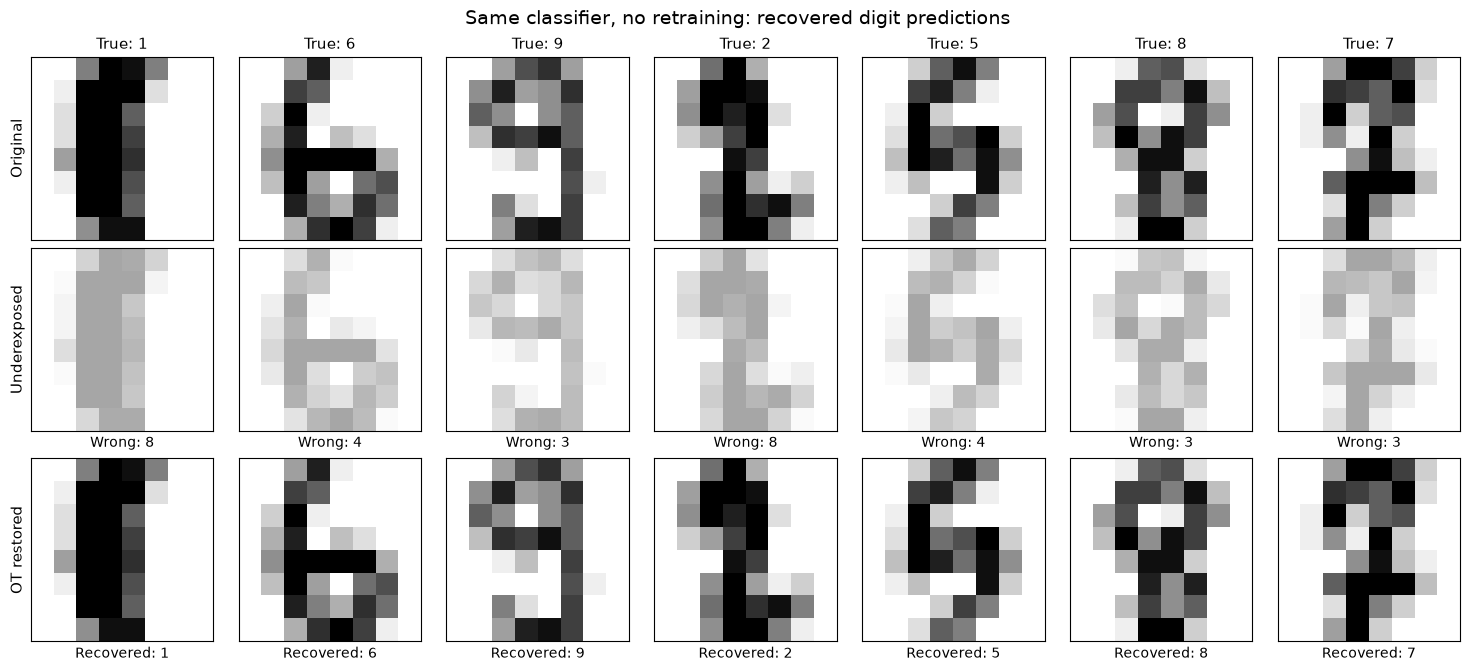

In [4]:
# VISUAL PROOF: clean digit / camera darkening / recovered image + predictions.
# Prefer varied true digit labels when choosing corrected examples.
ot_show = []
ot_seen = set()
for ot_idx in ot_rescued:
    ot_label = int(ot_y_test[ot_idx])
    if ot_label not in ot_seen:
        ot_show.append(int(ot_idx))
        ot_seen.add(ot_label)
    if len(ot_show) >= 7:
        break
if len(ot_show) < 7:
    ot_show += [int(i) for i in ot_rescued if int(i) not in ot_show][:7-len(ot_show)]

if not ot_show:
    print("No individually rescued predictions found for this setting. "
          "Try ot_exposure = 0.25 and rerun the experiment.")
else:
    ot_fig, ot_ax = plt.subplots(3, len(ot_show), figsize=(2.1 * len(ot_show), 6.6),
                                 squeeze=False, constrained_layout=True)
    for col, idx in enumerate(ot_show):
        images = (ot_X_test[idx], ot_X_dark[idx], ot_result_dark["corrected"][idx])
        for row, image in enumerate(images):
            ax = ot_ax[row, col]
            ax.imshow(image.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1,
                      interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
        ot_ax[0, col].set_title(f"True: {ot_y_test[idx]}", fontsize=11)
        ot_ax[1, col].set_xlabel(f"Wrong: {ot_pred_dark[idx]}", fontsize=10)
        ot_ax[2, col].set_xlabel(f"Recovered: {ot_pred_fixed[idx]}", fontsize=10)
    for row, label in enumerate(("Original", "Underexposed", "OT restored")):
        ot_ax[row, 0].set_ylabel(label, fontsize=11)
    ot_fig.suptitle("Same classifier, no retraining: recovered digit predictions", fontsize=14)
    plt.show()

## Live prediction demonstration


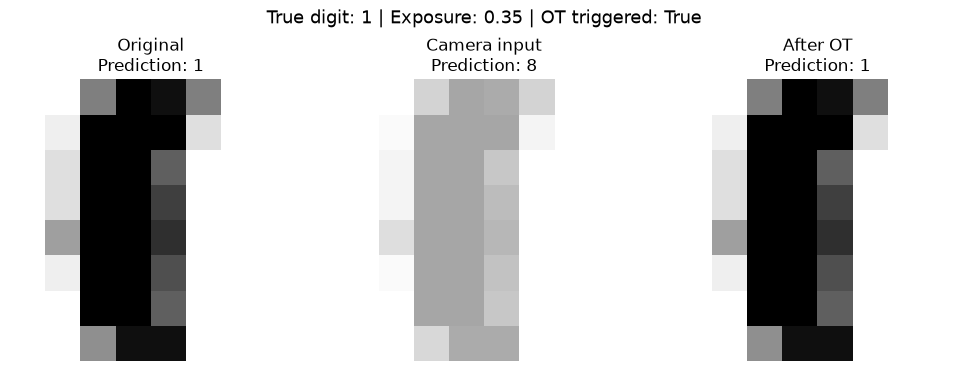

Shift W1: 0.3883  |  Raw: 8  →  After adaptation: 1  |  True: 1


In [5]:
def ot_shift_demo(index=0, exposure=0.35):
    """Display one digit undergoing camera shift and label-free OT restoration."""
    if not 0 <= index < len(ot_X_test):
        raise IndexError(f"index must lie in [0, {len(ot_X_test)-1}]")
    if not 0.2 <= exposure <= 1.0:
        raise ValueError("exposure must be in [0.2, 1.0]")

    incoming = np.clip(ot_X_test * exposure, 0, 1)
    raw_predictions = ot_classifier.predict(incoming)
    adapt = ot_adaptive_predict(incoming)
    truth = int(ot_y_test[index])
    panels = [
        (ot_X_test[index], f"Original\nPrediction: {ot_classifier.predict(ot_X_test[index:index+1])[0]}"),
        (incoming[index], f"Camera input\nPrediction: {raw_predictions[index]}"),
        (adapt["corrected"][index],
         f"After OT\nPrediction: {adapt['predictions'][index]}"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), constrained_layout=True)
    for ax, (im, name) in zip(axes, panels):
        ax.imshow(im.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1,
                  interpolation="nearest")
        ax.set_title(name, fontsize=12)
        ax.axis("off")
    fig.suptitle(f"True digit: {truth} | Exposure: {exposure:.2f} | "
                 f"OT triggered: {adapt['triggered']}", fontsize=13)
    plt.show()
    print(f"Shift W1: {adapt['shift_w1']:.4f}  |  "
          f"Raw: {raw_predictions[index]}  →  "
          f"After adaptation: {adapt['predictions'][index]}  |  "
          f"True: {truth}")


# Example chosen because it was actually misclassified under exposure shift.
ot_demo_index = int(ot_rescued[0]) if len(ot_rescued) else 0
ot_shift_demo(index=ot_demo_index, exposure=ot_exposure)

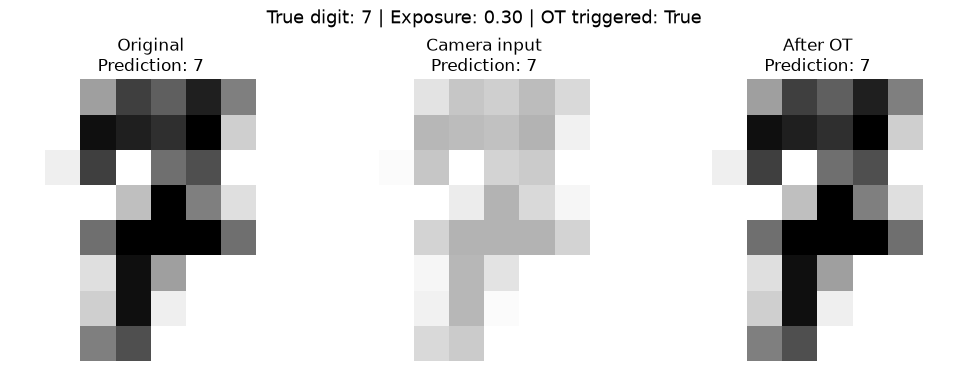

Shift W1: 0.4182  |  Raw: 7  →  After adaptation: 7  |  True: 7


In [6]:
ot_shift_demo(index=5, exposure=0.30)

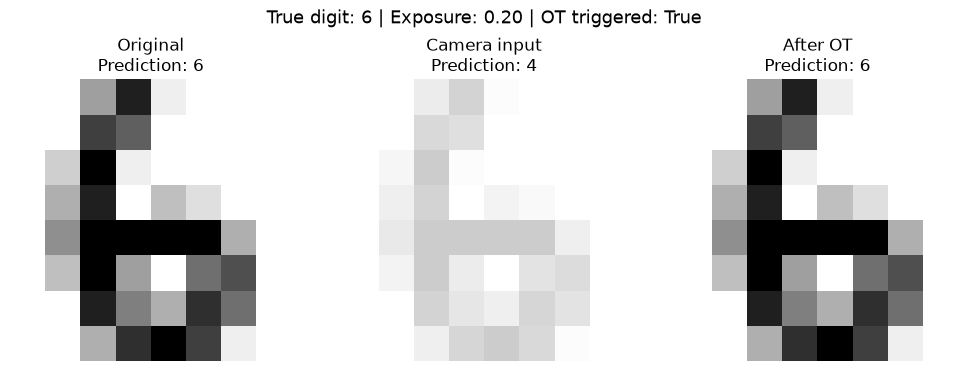

Shift W1: 0.4780  |  Raw: 4  →  After adaptation: 6  |  True: 6


In [8]:
ot_shift_demo(index=10, exposure=0.20)